In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:

!pip install pydub

import numpy as np
import matplotlib.pyplot as plt
from pydub import AudioSegment
from scipy import signal
from scipy.io import wavfile
import librosa
import os

# --- THIẾT LẬP BAN ĐẦU ---
# Dán đường dẫn tệp MP3 bạn vừa tải lên Colab vào đây
FILE_PATH = '/content/Nhac Chuong Yeu Em Rat Nhieu - Hoang Ton.mp3'

AUDIO_DIR = 'audio_output'
FIG_DIR = 'figures_output'
os.makedirs(AUDIO_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

# ==========================================
# A. ĐỌC VÀ KIỂM TRA DỮ LIỆU ÂM THANH
# ==========================================
print("--- PHẦN A: ĐỌC DỮ LIỆU ---")
audio = AudioSegment.from_file(FILE_PATH)
Fs = audio.frame_rate
channels = audio.channels
sample_width = audio.sample_width
duration = len(audio) / 1000.0

print(f"Sampling rate (Fs): {Fs} Hz")
print(f"Số kênh: {channels}")
print(f"Thời lượng: {duration} s")
print(f"Độ rộng mẫu: {sample_width * 8} bit")

mono_audio = audio.set_channels(1)
x = np.array(mono_audio.get_array_of_samples(), dtype=np.float64)
x = x / (2**(8 * sample_width - 1))

--- PHẦN A: ĐỌC DỮ LIỆU ---
Sampling rate (Fs): 44100 Hz
Số kênh: 2
Thời lượng: 30.605 s
Độ rộng mẫu: 16 bit



--- PHẦN B: MIỀN THỜI GIAN ---
Peak: 1.0000 (Clipping nguy cơ: Không)
RMS: 0.2231
Năng lượng (E): 67185.7026


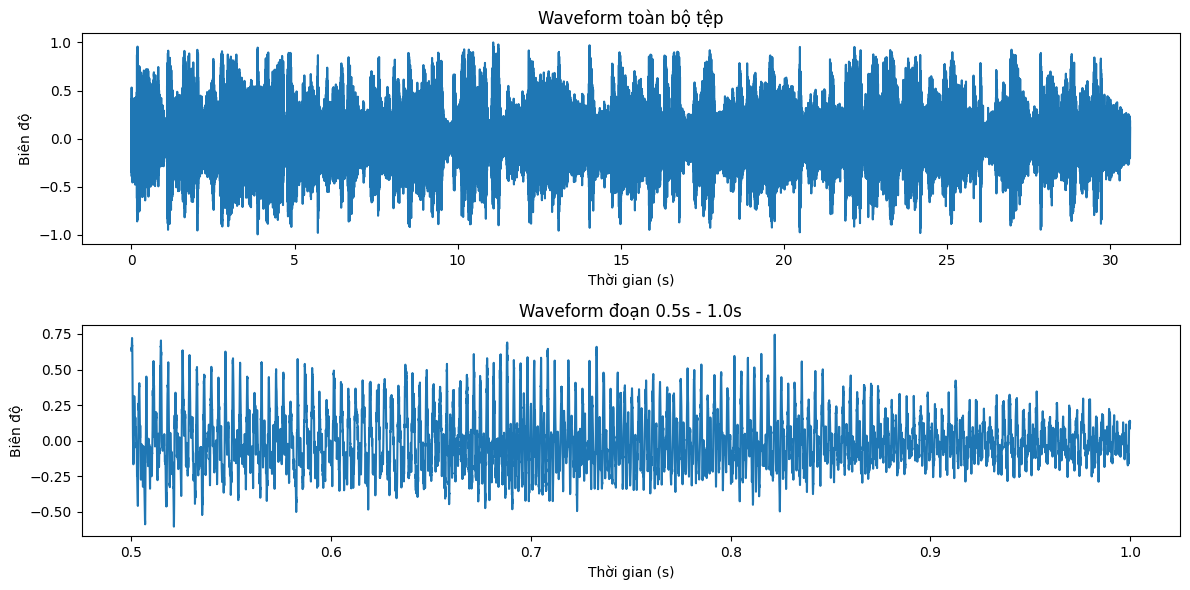

In [6]:
# ==========================================
# B. PHÂN TÍCH MIỀN THỜI GIAN
# ==========================================
print("\n--- PHẦN B: MIỀN THỜI GIAN ---")
peak = np.max(np.abs(x))
rms = np.sqrt(np.mean(x**2))
energy = np.sum(x**2)
print(f"Peak: {peak:.4f} (Clipping nguy cơ: {'Có' if peak >= 1.0 else 'Không'})")
print(f"RMS: {rms:.4f}")
print(f"Năng lượng (E): {energy:.4f}")

time_axis = np.arange(len(x)) / Fs
plt.figure(figsize=(12, 6))

plt.subplot(2, 1, 1)
plt.plot(time_axis, x)
plt.title('Waveform toàn bộ tệp')
plt.xlabel('Thời gian (s)')
plt.ylabel('Biên độ')

# Trích xuất 0.5s để nhìn rõ chu kỳ sóng của giọng hát
start_idx = int(0.5 * Fs)
end_idx = int(1.0 * Fs)
plt.subplot(2, 1, 2)
plt.plot(time_axis[start_idx:end_idx], x[start_idx:end_idx])
plt.title('Waveform đoạn 0.5s - 1.0s')
plt.xlabel('Thời gian (s)')
plt.ylabel('Biên độ')

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/waveform.png")
plt.show()


--- PHẦN C: FFT ---


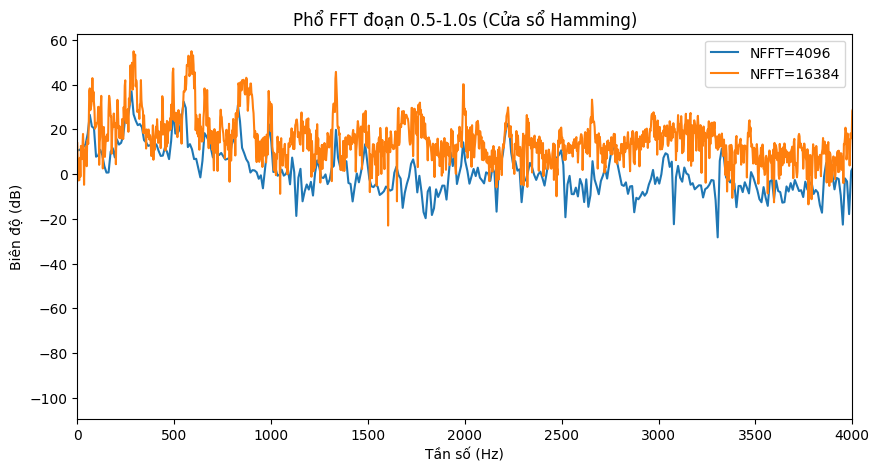

In [7]:
# ==========================================
# C. PHÂN TÍCH MIỀN TẦN SỐ BẰNG FFT
# ==========================================
print("\n--- PHẦN C: FFT ---")
seg = x[start_idx:end_idx]
w = np.hamming(len(seg))

nfft_1 = 4096
nfft_2 = 16384

def plot_fft(segment, window, nfft, title):
    X = np.fft.rfft(segment * window, n=nfft)
    f = np.fft.rfftfreq(nfft, 1/Fs)
    mag_db = 20 * np.log10(np.maximum(np.abs(X), 1e-12))

    plt.plot(f, mag_db, label=f'NFFT={nfft}')
    return f, mag_db

plt.figure(figsize=(10, 5))
plot_fft(seg, w, nfft_1, "NFFT = 4096")
plot_fft(seg, w, nfft_2, "NFFT = 16384")

plt.title('Phổ FFT đoạn 0.5-1.0s (Cửa sổ Hamming)')
plt.xlabel('Tần số (Hz)')
plt.ylabel('Biên độ (dB)')
plt.legend()
plt.xlim(0, 4000) # Giới hạn 4kHz để thấy rõ các đỉnh tần số của giọng hát
plt.savefig(f"{FIG_DIR}/fft.png")
plt.show()



--- PHẦN D: SPECTROGRAM ---


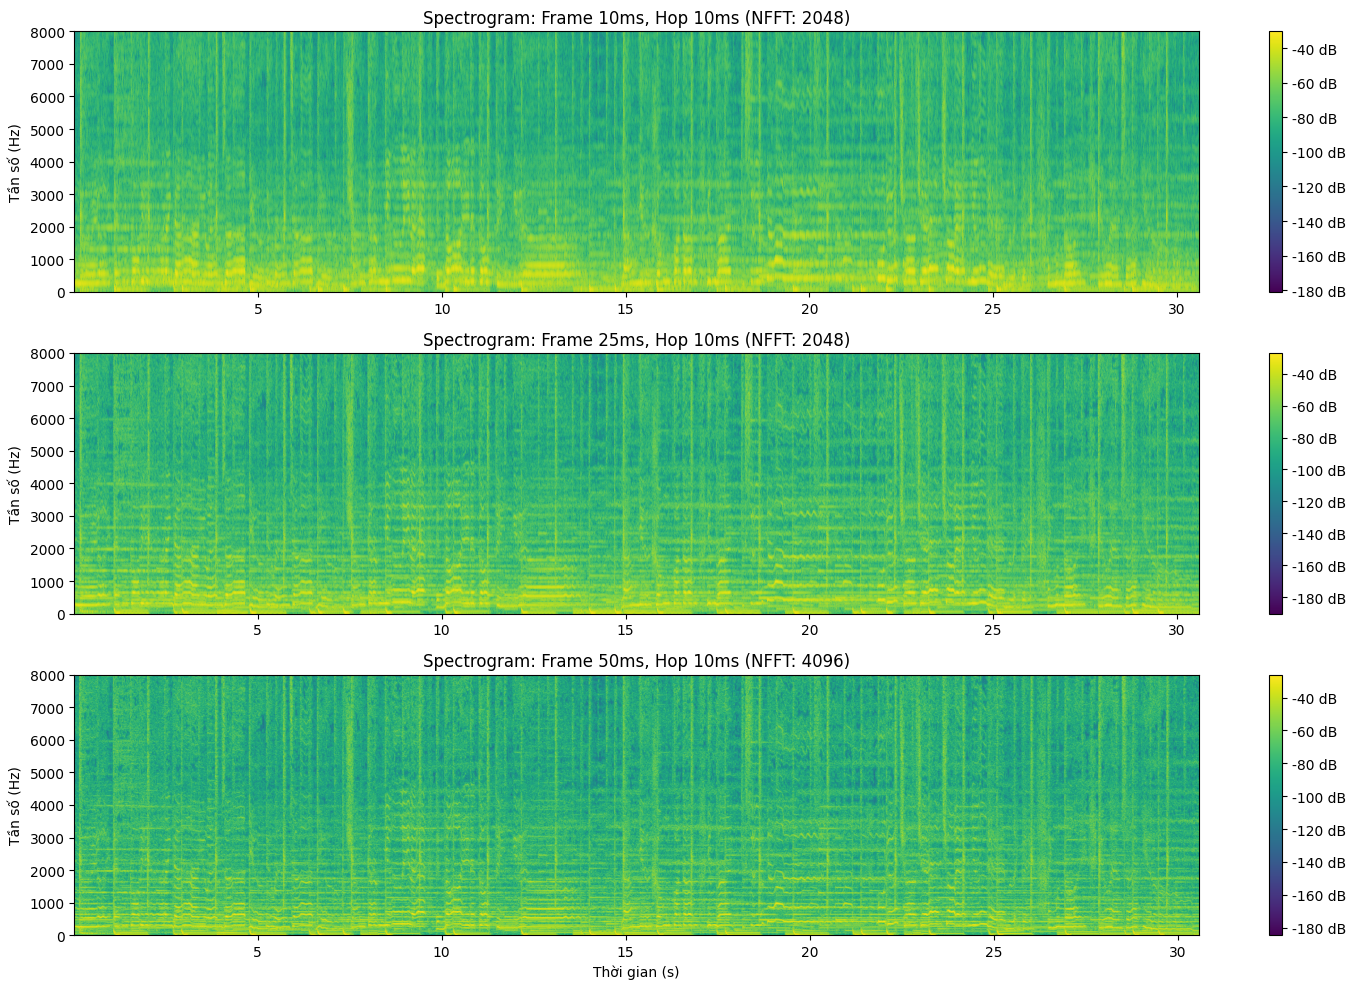

In [8]:
# ==========================================
# D. STFT VÀ SPECTROGRAM
# ==========================================
print("\n--- PHẦN D: SPECTROGRAM ---")
frames_ms = [10, 25, 50]
plt.figure(figsize=(15, 10))

for i, f_ms in enumerate(frames_ms):
    L = int(f_ms / 1000 * Fs)
    H = int(10 / 1000 * Fs)

    # Tự động tính NFFT: lớn hơn hoặc bằng L, làm tròn lên lũy thừa của 2, tối thiểu là 2048
    nfft_val = max(2048, int(2**np.ceil(np.log2(L))))

    f, t, Sxx = signal.spectrogram(x, fs=Fs, window='hamming',
                                   nperseg=L, noverlap=L-H, nfft=nfft_val, mode='magnitude')
    S_dB = 20 * np.log10(np.maximum(Sxx, 1e-12))

    plt.subplot(3, 1, i+1)
    plt.pcolormesh(t, f, S_dB, shading='gouraud', cmap='viridis')
    plt.title(f'Spectrogram: Frame {f_ms}ms, Hop 10ms (NFFT: {nfft_val})')
    plt.ylabel('Tần số (Hz)')
    plt.colorbar(format='%+2.0f dB')
    plt.ylim(0, 8000) # Giới hạn trục Y để quan sát cấu trúc harmonic

plt.xlabel('Thời gian (s)')
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/spectrogram.png")
plt.show()



--- PHẦN E: SO SÁNH CỬA SỔ ---


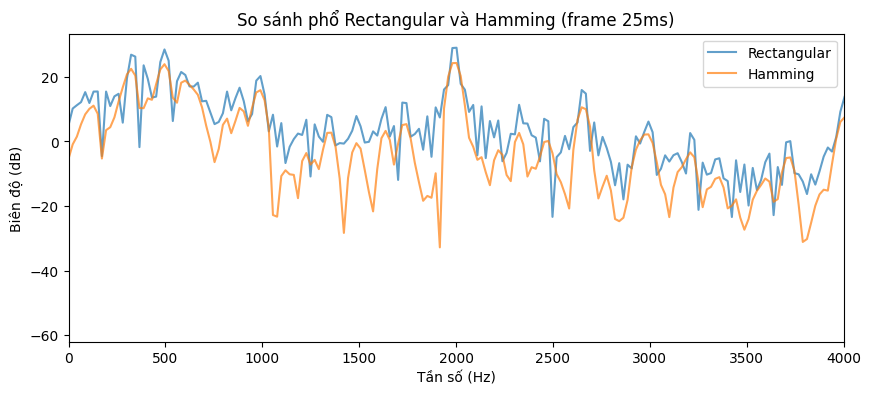

In [9]:
# ==========================================
# E. THÍ NGHIỆM CỬA SỔ
# ==========================================
print("\n--- PHẦN E: SO SÁNH CỬA SỔ ---")
frame_len = int(0.025 * Fs)
frame_seg = x[int(1.0*Fs) : int(1.0*Fs) + frame_len]

w_rect = np.ones(frame_len)
w_hamm = np.hamming(frame_len)
nfft_E = 2048

X_rect = 20 * np.log10(np.maximum(np.abs(np.fft.rfft(frame_seg * w_rect, n=nfft_E)), 1e-12))
X_hamm = 20 * np.log10(np.maximum(np.abs(np.fft.rfft(frame_seg * w_hamm, n=nfft_E)), 1e-12))
f_E = np.fft.rfftfreq(nfft_E, 1/Fs)

plt.figure(figsize=(10, 4))
plt.plot(f_E, X_rect, label='Rectangular', alpha=0.7)
plt.plot(f_E, X_hamm, label='Hamming', alpha=0.7)
plt.title('So sánh phổ Rectangular và Hamming (frame 25ms)')
plt.xlabel('Tần số (Hz)')
plt.ylabel('Biên độ (dB)')
plt.xlim(0, 4000)
plt.legend()
plt.show()


--- PHẦN F: LỌC SỐ ---


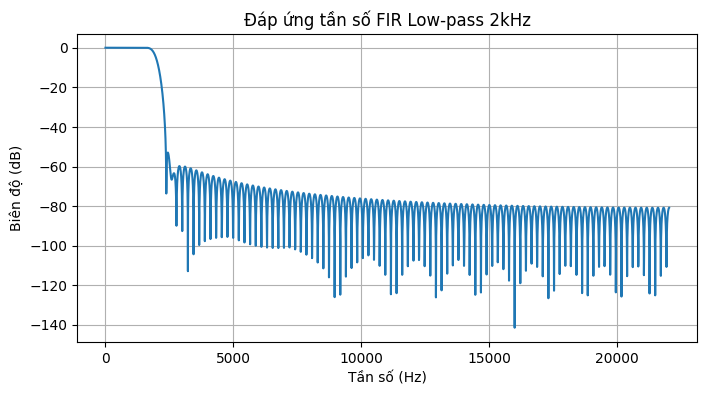

In [10]:
# ==========================================
# F. LỌC SỐ (FIR)
# ==========================================
print("\n--- PHẦN F: LỌC SỐ ---")
b_low = signal.firwin(numtaps=201, cutoff=2000, fs=Fs, window='hamming')
y_low = signal.lfilter(b_low, [1.0], x)
wavfile.write(f"{AUDIO_DIR}/filtered_lowpass_2k.wav", Fs, np.int16(y_low * 32767))

b_high = signal.firwin(numtaps=201, cutoff=1000, fs=Fs, pass_zero=False, window='hamming')
y_high = signal.lfilter(b_high, [1.0], x)
wavfile.write(f"{AUDIO_DIR}/filtered_highpass_1k.wav", Fs, np.int16(y_high * 32767))

w_freq, h_freq = signal.freqz(b_low, worN=4096, fs=Fs)
plt.figure(figsize=(8, 4))
plt.plot(w_freq, 20 * np.log10(np.maximum(np.abs(h_freq), 1e-12)))
plt.title('Đáp ứng tần số FIR Low-pass 2kHz')
plt.xlabel('Tần số (Hz)')
plt.ylabel('Biên độ (dB)')
plt.grid()
plt.savefig(f"{FIG_DIR}/filter_response.png")
plt.show()


In [11]:
# ==========================================
# G. LƯỢNG TỬ HÓA VÀ RESAMPLING
# ==========================================
print("\n--- PHẦN G: QUANTIZATION & RESAMPLING ---")

def quantize_and_snr(sig, B):
    qmax = 2**(B-1) - 1
    xq = np.round(np.clip(sig, -1, 1) * qmax) / qmax
    e = xq - sig
    snr = 10 * np.log10(np.sum(sig**2) / np.sum(e**2))
    return xq, snr

bits_to_test = [4, 8, 16]
for b in bits_to_test:
    xq, snr_val = quantize_and_snr(x, b)
    print(f"SNR lượng tử {b}-bit: {snr_val:.2f} dB")
    wavfile.write(f"{AUDIO_DIR}/quantized_{b}bit.wav", Fs, np.int16(xq * 32767))

x_16k = librosa.resample(y=x, orig_sr=Fs, target_sr=16000)
x_8k = librosa.resample(y=x, orig_sr=Fs, target_sr=8000)
wavfile.write(f"{AUDIO_DIR}/resampled_16k.wav", 16000, np.int16(x_16k * 32767))
wavfile.write(f"{AUDIO_DIR}/resampled_8k.wav", 8000, np.int16(x_8k * 32767))

R_PCM = Fs * 16 * 2
size_pcm_MB = (R_PCM * duration / 8) / (1024 * 1024)
file_size_bytes = os.path.getsize(FILE_PATH)
file_size_MB = file_size_bytes / (1024 * 1024)
bitrate_kbps = (file_size_bytes * 8) / duration / 1000

print(f"\nTốc độ bit PCM 16-bit lý thuyết: {R_PCM/1000:.1f} kbps")
print(f"Kích thước PCM lý thuyết: {size_pcm_MB:.2f} MB")
print(f"Tốc độ bit file nén gốc: {bitrate_kbps:.1f} kbps (Size: {file_size_MB:.2f} MB)")
print(f"Compression Ratio: {R_PCM / (bitrate_kbps*1000):.2f}:1")


--- PHẦN G: QUANTIZATION & RESAMPLING ---
SNR lượng tử 4-bit: 14.67 dB
SNR lượng tử 8-bit: 39.84 dB
SNR lượng tử 16-bit: 90.99 dB

Tốc độ bit PCM 16-bit lý thuyết: 1411.2 kbps
Kích thước PCM lý thuyết: 5.15 MB
Tốc độ bit file nén gốc: 123.2 kbps (Size: 0.45 MB)
Compression Ratio: 11.46:1
